# Processing for all models 

In [1]:
#Import everything
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
import cftime
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.patches as mpatches
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr
from scipy import stats
from numpy import mean
from numpy import std
from numpy import absolute
from pandas import read_csv
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from sklearn.decomposition import PCA
from sklearn import preprocessing

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib as mpl
import matplotlib.colors as mcolors
from matplotlib.colors import BoundaryNorm, ListedColormap, TwoSlopeNorm
import matplotlib.cm as cm
from matplotlib.colors import TwoSlopeNorm
import joblib
from matplotlib.backends.backend_pdf import PdfPages

In [2]:
tos_HadGem3_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/tos_HadGEM3-GC31-LL_piControl_remap.nc")
tos_MPI_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/tos_MPI-ESM1-2-LR_piControl_remap.nc")
tos_CESM2_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/tos_CESM2_piControl_remap.nc")
tos_MRI_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/tos_MRI-ESM2-0_piControl_remap.nc")
tos_CanESM5_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/tos_CanESM5_piControl_remap.nc")

/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/coding/times.py:724: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/coding/times.py:724: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/core/indexing.py:557: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  array = array.get_duck_array()
/home/baharem/.conda/envs/baharenv/lib/python3.12/si

In [3]:
sos_HadGem3_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/sos_HadGEM3-GC31-LL_piControl_remap.nc")
sos_MPI_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/sos_MPI-ESM1-2-LR_piControl_remap.nc")
sos_CESM2_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/sos_CESM2_piControl_remap.nc")
sos_MRI_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/sos_MRI-ESM2-0_piControl_remap.nc")
sos_CanESM5_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/sos_CanESM5_piControl_remap.nc")

/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/coding/times.py:724: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/coding/times.py:724: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/core/indexing.py:557: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  array = array.get_duck_array()
/home/baharem/.conda/envs/baharenv/lib/python3.12/si

In [4]:
sos_MRI_pi

<xarray.Dataset>
Dimensions:    (time: 701, bnds: 2, lon: 360, lat: 180)
Coordinates:
  * time       (time) object 1850-07-01 06:00:00 ... 2550-07-01 06:00:00
  * lon        (lon) float64 -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
  * lat        (lat) float64 -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) object ...
    sos        (time, lat, lon) float32 ...
Attributes: (12/46)
    CDI:                    Climate Data Interface version 2.4.2 (https://mpi...
    Conventions:            CF-1.7 CMIP-6.2
    source:                 MRI-ESM2.0 (2017): \naerosol: MASINGAR mk2r4 (TL9...
    institution:            Meteorological Research Institute, Tsukuba, Ibara...
    activity_id:            CMIP
    branch_method:          standard
    ...                     ...
    variable_id:            sos
    variant_label:          r1i1p1f1
    license:                CMIP6 model data produced by MRI is licensed unde...
    cmor_version:           3.5.0
    tracking_id:            hdl:21.14100/ae0abeb2-2cf0-411a-816f-20a8d474ff07
    CDO:                    Climate Data Operators version 2.4.2 (https://mpi...

In [5]:
tos_HadGem3_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/tos_HadGEM3-GC31-LL_historical_remap.nc")
tos_MPI_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/tos_MPI-ESM1-2-LR_historical_remap.nc")
tos_CESM2_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/tos_CESM2_historical_remap.nc")
tos_MRI_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/tos_MRI-ESM2-0_historical_remap.nc")
tos_CanESM5_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/tos_CanESM5_historical_remap.nc")

In [6]:
sos_HadGem3_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/sos_HadGEM3-GC31-LL_historical_remap.nc")
sos_MPI_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/sos_MPI-ESM1-2-LR_historical_remap.nc")
sos_CESM2_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/sos_CESM2_historical_remap.nc")
sos_MRI_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/sos_MRI-ESM2-0_historical_remap.nc")
sos_CanESM5_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/sos_CanESM5_historical_remap.nc")

In [7]:
msftmz_HadGem3_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftyz_HadGEM3-GC31-LL_piControl_yearmean.nc")
msftmz_MPI_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftmz_MPI-ESM1-2-LR_piControl_yearmean.nc")
msftmz_CESM2_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftmz_CESM2_piControl_yearmean.nc")
msftmz_MRI_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftyz_MRI-ESM2-0_piControl_yearmean.nc")
msftmz_CanESM5_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftmz_CanESM5_piControl_yearmean.nc")

/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/coding/times.py:724: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/coding/times.py:724: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/core/indexing.py:557: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  array = array.get_duck_array()
/home/baharem/.conda/envs/baharenv/lib/python3.12/si

In [8]:
msftmz_HadGem3_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftyz_HadGEM3-GC31-LL_historical_yearmean.nc")
msftmz_MPI_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftmz_MPI-ESM1-2-LR_historical_yearmean.nc")
msftmz_CESM2_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftmz_CESM2_historical_yearmean.nc")
msftmz_MRI_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftyz_MRI-ESM2-0_historical_yearmean.nc")
msftmz_CanESM5_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftmz_CanESM5_historical_yearmean.nc")

In [12]:
tos_CESM2_pi

<xarray.Dataset>
Dimensions:    (time: 1200, bnds: 2, lon: 360, lat: 180)
Coordinates:
  * time       (time) object 0001-06-30 06:00:00 ... 1200-06-30 06:00:00
  * lon        (lon) float64 -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
  * lat        (lat) float64 -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) object ...
    tos        (time, lat, lon) float32 ...
Attributes: (12/44)
    CDI:                    Climate Data Interface version 2.4.2 (https://mpi...
    Conventions:            CF-1.7 CMIP-6.2
    source:                 CESM2 (2017): atmosphere: CAM6 (0.9x1.25 finite v...
    institution:            National Center for Atmospheric Research, Climate...
    activity_id:            CMIP
    case_id:                3
    ...                     ...
    variant_label:          r1i1p1f1
    branch_time_in_parent:  48545.0
    branch_time_in_child:   0.0
    branch_method:          standard
    history:                Mon Dec 08 10:08:21 2025: cdo remapbil,/p/tmp/bah...
    CDO:                    Climate Data Operators version 2.4.2 (https://mpi...

In [13]:
msftbarot_HadGem3_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftbarot_HadGEM3-GC31-LL_piControl_remap.nc")
msftbarot_MPI_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftbarot_MPI-ESM1-2-LR_piControl_remap.nc")
msftbarot_CESM2_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftbarot_CESM2_piControl_remap.nc")
msftbarot_MRI_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftbarot_MRI-ESM2-0_piControl_remap.nc")
msftbarot_CanESM5_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftbarot_CanESM5_piControl_remap.nc")

/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/coding/times.py:724: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/coding/times.py:724: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/core/indexing.py:557: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  array = array.get_duck_array()
/home/baharem/.conda/envs/baharenv/lib/python3.12/si

In [14]:
msftbarot_HadGem3_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftbarot_HadGEM3-GC31-LL_historical_remap.nc")
msftbarot_MPI_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftbarot_MPI-ESM1-2-LR_historical_remap.nc")
msftbarot_CESM2_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftbarot_CESM2_historical_remap.nc")
msftbarot_MRI_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftbarot_MRI-ESM2-0_historical_remap.nc")
msftbarot_CanESM5_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/processing/msftbarot_CanESM5_historical_remap.nc")

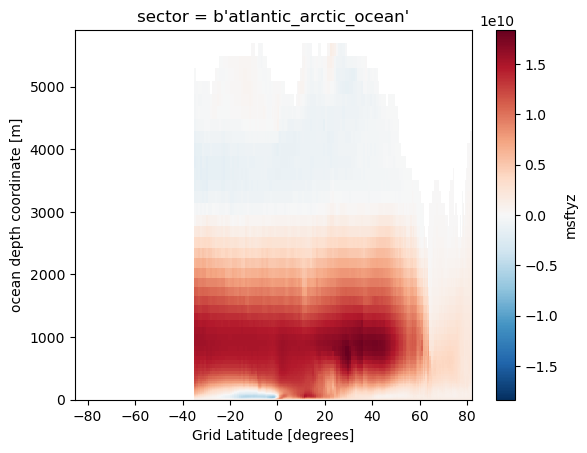

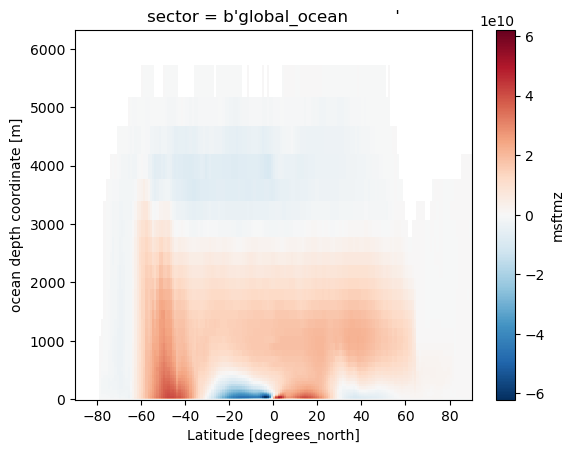

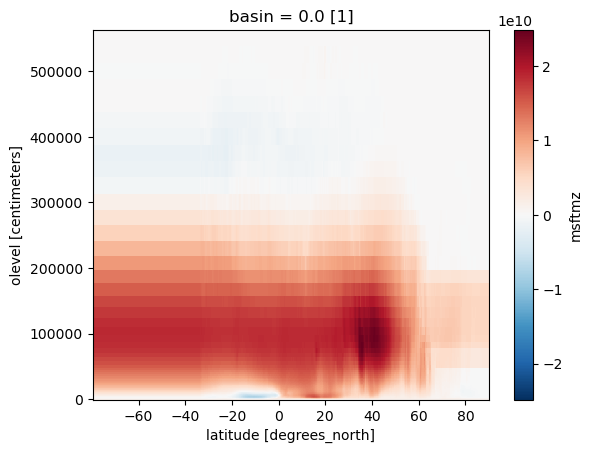

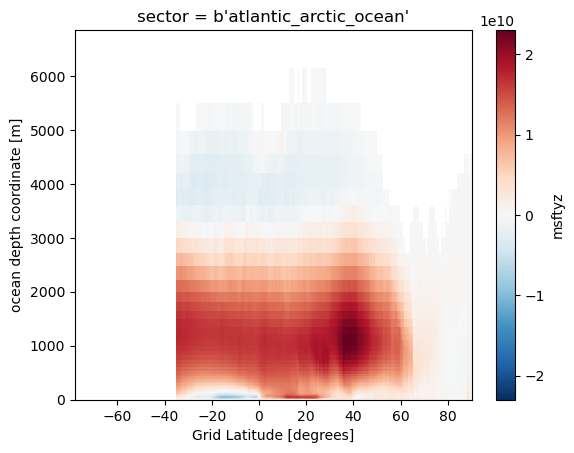

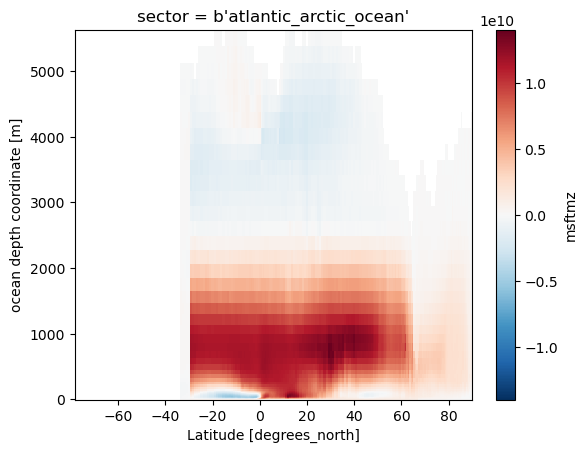

In [15]:
all_models = ["HadGem3", "MPI", "CESM2", "MRI", "CanESM5"]

for model in all_models:
    ds_pi = globals()[f"msftmz_{model}_pi"]  #  datasets
    ds_hist=globals()[f"msftmz_{model}_hist"]  # datasets

    # find the variable name (msftmz or msftyz etc.)
    varname = None
    for candidate in ["msftmz", "msftyz"]:
        if candidate in ds_pi.data_vars:
            varname = candidate
            break
    
    if varname is None:
        print(f"{model}: no msftmz/msftyz found")
        continue
    
    # select basin 0, time mean
    da_pi = ds_pi[varname].sel(basin=0).mean(dim="time")
    da_hist=ds_hist[varname].sel(basin=0).mean(dim="time")
    # create a new figure for each plot
    plt.figure()
    da_hist.plot()
    #plt.title(f"{model} - basin 0 mean")
    plt.show()


In [16]:
def process_moc_xr(da):
    # da is an xarray DataArray with time
    mean = da.mean("time")
    da = (da - mean) * 1e-9  # Sv
    #da = da.rolling(time=5, center=True).mean()
    da = da.dropna("time")

    return da.to_pandas().reset_index(drop=True)


In [17]:
#Processing mocs 
#HADGEM3

da = (
    msftmz_HadGem3_pi["msftyz"]
    .sel(basin=0)
    .sel(rlat=40, method="nearest")
    .sel(lev=slice(0, 2000))
    .max(dim="lev")
)

moc_HadGem3_pi = process_moc_xr(da)

joblib.dump(moc_HadGem3_pi, "/p/tmp/baharem/August_25/processing/processed_dfs/moc_HadGem3_pi")


da_hist = (
    msftmz_HadGem3_hist["msftyz"]
    .sel(basin=0)
    .sel(rlat=40, method="nearest")
    .sel(lev=slice(0, 2000))
    .max(dim="lev")
)

moc_HadGem3_hist = process_moc_xr(da_hist)

joblib.dump(moc_HadGem3_hist, "/p/tmp/baharem/August_25/processing/processed_dfs/moc_HadGem3_hist")


['/p/tmp/baharem/August_25/processing/processed_dfs/moc_HadGem3_hist']

In [18]:
#Processing mocs 
#MPI

da = (
    msftmz_MPI_pi["msftmz"]
    .sel(basin=1) # basin=1 is atlantic for mpi
    .sel(lat=40, method="nearest")
    .sel(lev=slice(0, 2000))
    .max(dim="lev")
)

moc_MPI_pi = process_moc_xr(da)

joblib.dump(moc_MPI_pi, "/p/tmp/baharem/August_25/processing/processed_dfs/moc_MPI_pi")


da_hist = (
    msftmz_MPI_hist["msftmz"]
    .sel(basin=1) # basin=1 is atlantic for mpi
    .sel(lat=40, method="nearest")
    .sel(lev=slice(0, 2000))
    .max(dim="lev")
)

moc_MPI_hist = process_moc_xr(da_hist)

joblib.dump(moc_MPI_hist, "/p/tmp/baharem/August_25/processing/processed_dfs/moc_MPI_hist")

['/p/tmp/baharem/August_25/processing/processed_dfs/moc_MPI_hist']

In [19]:
msftmz_CESM2_pi

<xarray.Dataset>
Dimensions:    (time: 1200, bnds: 2, basin: 3, lat: 395, lev: 61)
Coordinates:
  * time       (time) object 0001-06-30 06:00:00 ... 1200-06-30 06:00:00
  * basin      (basin) float64 0.0 1.0 2.0
  * lat        (lat) float64 -79.49 -78.95 -78.42 -77.88 ... 88.95 89.47 90.0
  * lev        (lev) float64 0.0 1e+03 2e+03 3e+03 ... 5e+05 5.25e+05 5.5e+05
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) object ...
    lat_bnds   (lat, bnds) float64 ...
    lev_bnds   (lev, bnds) float64 ...
    msftmz     (time, basin, lev, lat) float32 ...
Attributes: (12/43)
    CDI:                    Climate Data Interface version 2.4.2 (https://mpi...
    Conventions:            CF-1.7 CMIP-6.2
    source:                 CESM2 (2017): atmosphere: CAM6 (0.9x1.25 finite v...
    institution:            National Center for Atmospheric Research, Climate...
    activity_id:            CMIP
    branch_method:          standard
    ...                     ...
    tracking_id:            hdl:21.14100/7cd53f5e-046a-4fe8-a079-b0029bfe32c9
    variable_id:            msftmz
    variant_info:           CMIP6 CESM2 piControl experiment with CAM6, inter...
    variant_label:          r1i1p1f1
    history:                Mon Dec 08 13:44:41 2025: cdo yearmean /p/tmp/bah...
    CDO:                    Climate Data Operators version 2.4.2 (https://mpi...

In [20]:
#Processing mocs 
#CESM2

da = (
    msftmz_CESM2_pi["msftmz"]
    .sel(basin=0) 
    .sel(lat=40, method="nearest")
    .sel(lev=slice(0, 200000)) #units are in cm for CESM2
    .max(dim="lev")
)

moc_CESM2_pi = process_moc_xr(da)

joblib.dump(moc_CESM2_pi, "/p/tmp/baharem/August_25/processing/processed_dfs/moc_CESM2_pi")


da_hist = (
    msftmz_CESM2_hist["msftmz"]
    .sel(basin=0) 
    .sel(lat=40, method="nearest")
    .sel(lev=slice(0, 200000)) #units are in cm for CESM2
    .max(dim="lev")
)

moc_CESM2_hist = process_moc_xr(da_hist)

joblib.dump(moc_CESM2_hist, "/p/tmp/baharem/August_25/processing/processed_dfs/moc_CESM2_hist")


['/p/tmp/baharem/August_25/processing/processed_dfs/moc_CESM2_hist']

In [21]:
moc_CESM2_hist

0     -1.963471
1     -1.124717
2     -2.795215
3     -2.241225
4     -1.518356
         ...   
160   -3.021820
161   -1.821940
162   -2.071089
163   -1.540592
164   -2.739546
Length: 165, dtype: float32

In [22]:
#Processing mocs 
#MRI

da = (
    msftmz_MRI_pi["msftyz"]
    .sel(basin=0) 
    .sel(rlat=40, method="nearest")
    .sel(lev=slice(0, 2000)) 
    .max(dim="lev")
)

moc_MRI_pi = process_moc_xr(da)

joblib.dump(moc_MRI_pi, "/p/tmp/baharem/August_25/processing/processed_dfs/moc_MRI_pi")


da_hist = (
    msftmz_MRI_hist["msftyz"]
    .sel(basin=0) 
    .sel(rlat=40, method="nearest")
    .sel(lev=slice(0, 2000)) 
    .max(dim="lev")
)

moc_MRI_hist = process_moc_xr(da_hist)

joblib.dump(moc_MRI_hist, "/p/tmp/baharem/August_25/processing/processed_dfs/moc_MRI_hist")



['/p/tmp/baharem/August_25/processing/processed_dfs/moc_MRI_hist']

In [23]:
#Processing mocs 
#CanESM5

da = (
    msftmz_CanESM5_pi["msftmz"]
    .sel(basin=0) 
    .sel(lat=40, method="nearest")
    .sel(lev=slice(0, 2000)) 
    .max(dim="lev")
)

moc_CanESM5_pi = process_moc_xr(da)

joblib.dump(moc_CanESM5_pi, "/p/tmp/baharem/August_25/processing/processed_dfs/moc_CanESM5_pi")


da_hist = (
    msftmz_CanESM5_hist["msftmz"]
    .sel(basin=0) 
    .sel(lat=40, method="nearest")
    .sel(lev=slice(0, 2000)) 
    .max(dim="lev")
)

moc_CanESM5_hist = process_moc_xr(da_hist)

joblib.dump(moc_CanESM5_hist, "/p/tmp/baharem/August_25/processing/processed_dfs/moc_CanESM5_hist")


['/p/tmp/baharem/August_25/processing/processed_dfs/moc_CanESM5_hist']

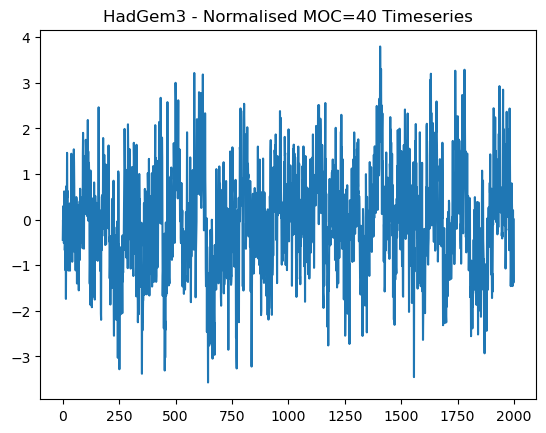

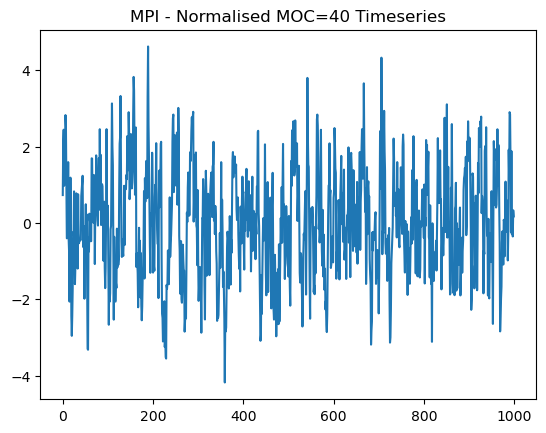

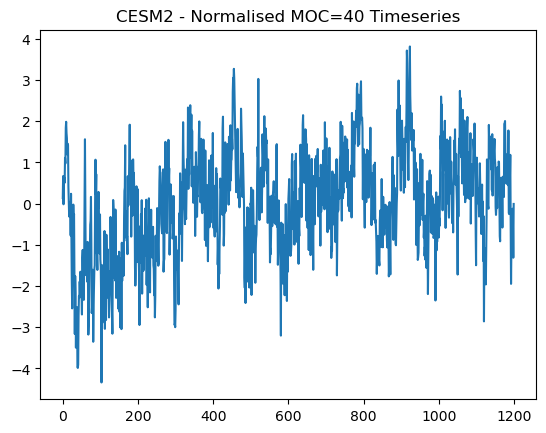

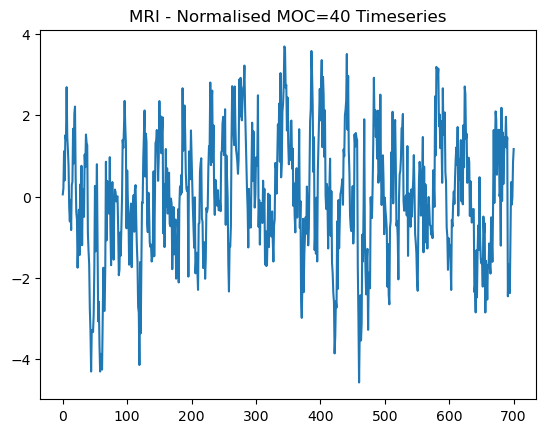

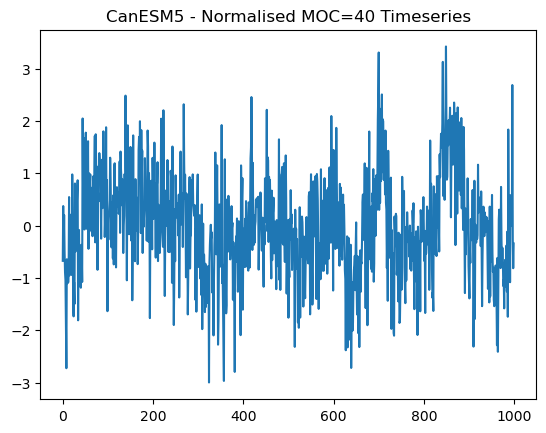

In [24]:
for model in all_models:
    # create a new figure for each plot
    df = globals()[f"moc_{model}_pi"]  # your datasets
    time=np.arange(0,len(df),1)
    plt.figure()
    plt.plot(time,df)
    plt.title(f"{model} - Normalised MOC=40 Timeseries")
    plt.show()


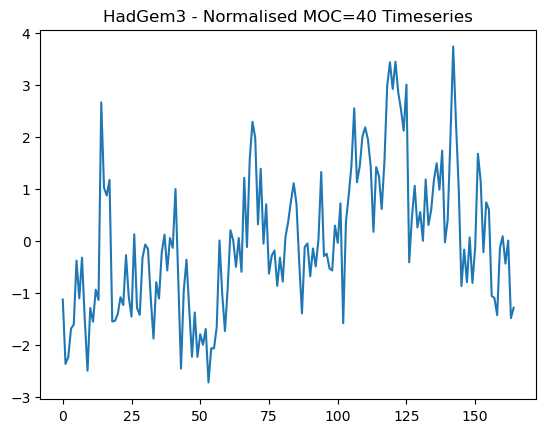

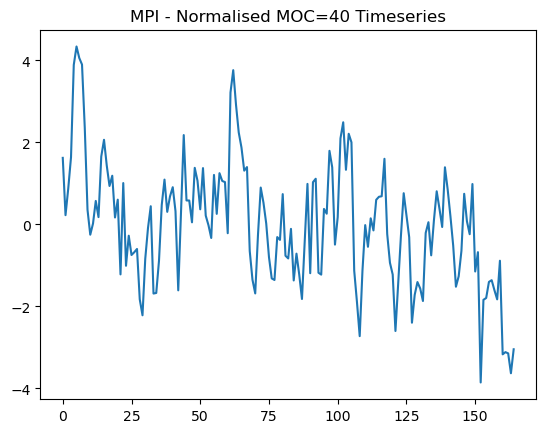

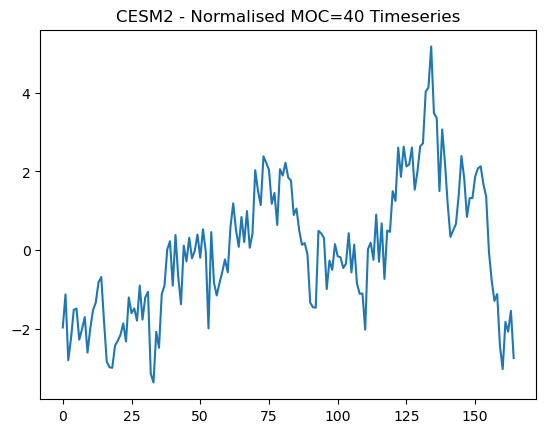

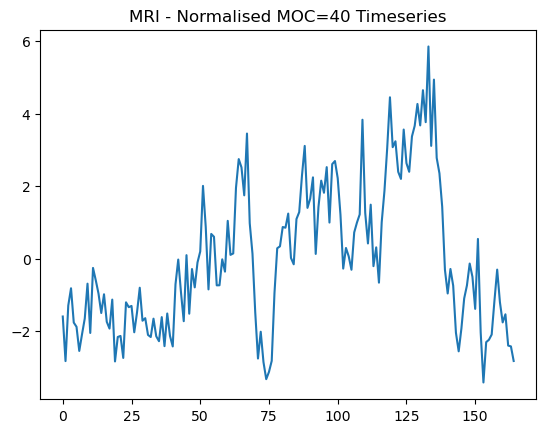

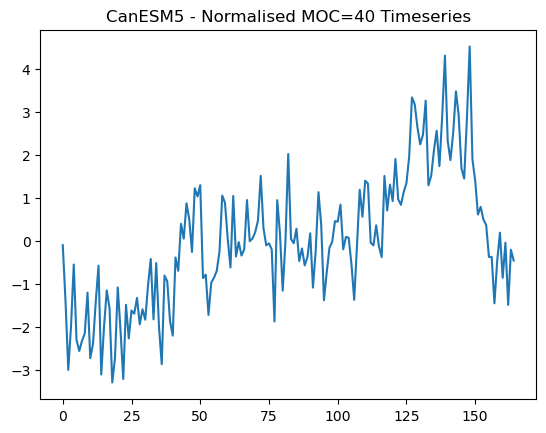

In [25]:
for model in all_models:
    # create a new figure for each plot
    df = globals()[f"moc_{model}_hist"]  # your datasets
    time=np.arange(0,len(df),1)
    plt.figure()
    plt.plot(time,df)
    plt.title(f"{model} - Normalised MOC=40 Timeseries")
    plt.show()


In [26]:
def find_offset_msftbarot(da):
    "Yearly offset finder for the msftbarot parameter "
    target_lat = 70
    target_lon = -56

    da_msftbarot = da["msftbarot"]

    offset = (
        da_msftbarot
        .sel(lat=target_lat, lon=target_lon, method="nearest")
        .groupby("time.year")
        .mean()
    )
       
    da_normalised=da["msftbarot"].groupby("time.year")-offset
    return da_normalised

In [27]:
find_offset_msftbarot(msftbarot_CanESM5_pi)
find_offset_msftbarot(msftbarot_HadGem3_pi)

<xarray.DataArray 'msftbarot' (time: 2000, lat: 180, lon: 360)>
array([[[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        ...,
        [2.16214733e+09, 2.19093402e+09, 2.21926195e+09, ...,
         2.07297741e+09, 2.10317312e+09, 2.13289370e+09],
        [1.78798592e+09, 1.80025754e+09, 1.81248000e+09, ...,
         1.74403584e+09, 1.76329523e+09, 1.77566515e+09],
        [1.12450765e+09, 1.13029120e+09, 1.13600102e+09, ...,
         1.10669824e+09, 1.11271117e+09, 1.11865037e+09]],

       [[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
...
        [1.82975693e+09, 1.87344486e+09, 1.91690342e+09, ...,
         1.69734144e+09, 1.74170931e+09, 1.78584781e+09],
        [1.60328909e+09, 1.63463987e+09, 1.66585958e+09, ...,
         1.50756557e+09, 1.54016973e+09, 1.57179904e+09],
        [1.08907725e+09, 1.10037402e+09, 1.11154790e+09, ...,
         1.05450701e+09, 1.06614784e+09, 1.07767398e+09]],

       [[           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        ...,
        [1.61920614e+09, 1.65435802e+09, 1.68929690e+09, ...,
         1.51257088e+09, 1.54832077e+09, 1.58385766e+09],
        [1.41818266e+09, 1.44269312e+09, 1.46702336e+09, ...,
         1.34514278e+09, 1.36855552e+09, 1.39347558e+09],
        [1.11434138e+09, 1.12220570e+09, 1.12998810e+09, ...,
         1.09030605e+09, 1.09839974e+09, 1.10641152e+09]]], dtype=float32)
Coordinates:
  * time     (time) object 1850-07-01 00:00:00 ... 3849-07-01 00:00:00
  * lon      (lon) float64 -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
    year     (time) int64 1850 1851 1852 1853 1854 ... 3845 3846 3847 3848 3849

In [28]:
def find_offset_msftbarot(da):
    target_lat = 70
    target_lon = -56
    
    # time mean
    da_msftbarot = da["msftbarot"].mean(dim="time")
    
    # pick the point
    offset_val = da_msftbarot.sel(lat=target_lat, lon=target_lon, method="nearest")
    
    # print with formatting
    print(f"offset = {float(offset_val):.4f}")
    
    # normalise
   
    da_normalised=da["msftbarot"]-offset_val
    return da_normalised
    

In [29]:
def process_msftbarot(ds,
                       lat_name="lat", lon_name="lon", 
                       lat_min=0, lat_max=70, lon_min=-80, lon_max=20):
    """
    Extracts minimum msftbarot within a lat/lon box for each timestep,
    applies sign flip, z-score normalisation, and 5-year rolling mean.

    Returns a DataFrame with columns ["time", "min_value"].
    """

    

    # --- Fix longitude range if given in 0..360 ---
    lons = ds[lon_name]
    if lons.max() > 180:
        lons = (lons + 180) % 360 - 180

    # --- Mask the box ---
    mask = (
        (ds[lat_name] >= lat_min) &
        (ds[lat_name] <= lat_max) &
        (lons >= lon_min) &
        (lons <= lon_max)
    )

    # Apply mask
    da_box = ds.where(mask, drop=True)

    # --- Ensure time dimension exists ---
    if "time" not in da_box.dims:
        raise ValueError("Variable has no time dimension.")

    # --- Min for each time step ---
    min_ts = da_box.min(dim=("lat", "lon"))

    # --- Convert to DataFrame ---
    df = min_ts.to_dataframe(name="min_value").reset_index()

    # --- Remove accidental duplicates (HadGEM often has these) ---
    df = df.drop_duplicates(subset="time")

    # --- Flip sign so SPG min becomes positive and convert to Sv ---
    df["min_value"] = -df["min_value"]

    # --- Z-score normalisation ---
    mean = df["min_value"].mean()
    
    df["min_value"] = (df["min_value"] - mean)*10**(-9) # retain the Sv units here too

    # --- 5-year rolling mean ---
    #df["min_value"] = df["min_value"].rolling(window=5, center=True).mean()

    # --- Drop NaNs introduced by rolling ---
    df = df.dropna()

    return df

    

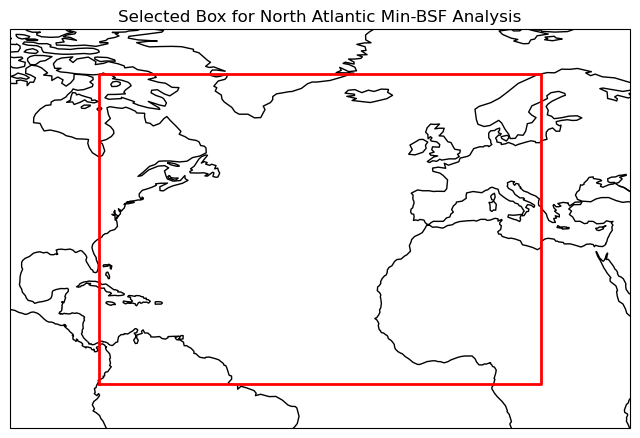

In [30]:
lat_min = 0
lat_max = 70
lon_min = -80
lon_max = 20

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

# Add coastlines for context
ax.coastlines()

# Set a reasonable domain around the Atlantic
ax.set_extent([-100, 40, -10, 80], crs=ccrs.PlateCarree())

# Draw your box
ax.plot(
    [lon_min, lon_max, lon_max, lon_min, lon_min],
    [lat_min, lat_min, lat_max, lat_max, lat_min],
    transform=ccrs.PlateCarree(),
    linewidth=2,
    color="red"
)

ax.set_title("Selected Box for North Atlantic Min-BSF Analysis")

plt.show()


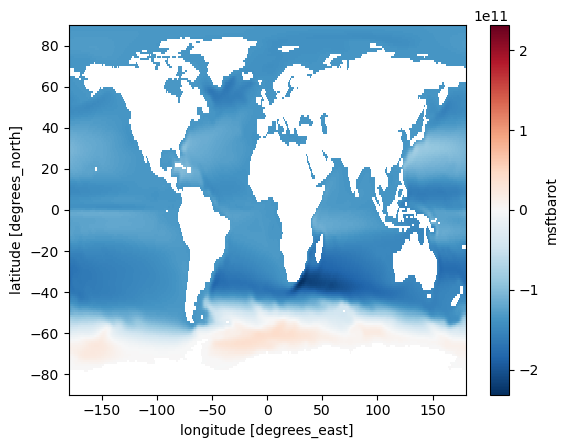

In [31]:
msftbarot_HadGem3_pi["msftbarot"].mean(dim="time").plot()

In [32]:
msftbarot_HadGem3_normalised_pi=find_offset_msftbarot(msftbarot_HadGem3_pi)

msftbarot_HadGem3_normalised_hist=find_offset_msftbarot(msftbarot_HadGem3_hist)

offset = -137062547456.0000
offset = -131885645824.0000


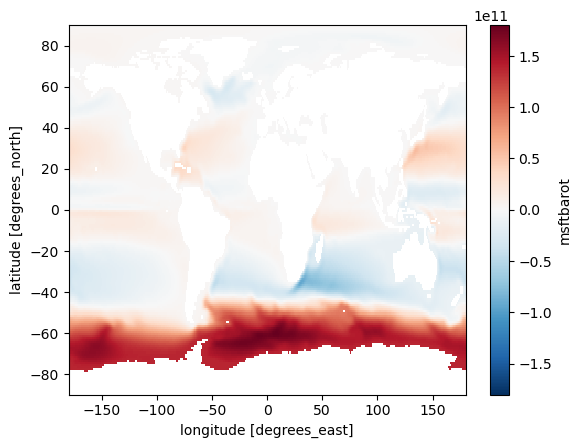

In [33]:
msftbarot_HadGem3_normalised_pi.mean(dim="time").plot()

In [34]:
msftbarot_HadGem3_normalised_pi_df=process_msftbarot(msftbarot_HadGem3_normalised_pi)
joblib.dump(msftbarot_HadGem3_normalised_pi_df, "/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_HadGem3_pi_df")
msftbarot_HadGem3_normalised_hist_df=process_msftbarot(msftbarot_HadGem3_normalised_hist)
joblib.dump(msftbarot_HadGem3_normalised_hist_df, "/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_HadGem3_hist_df")


['/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_HadGem3_hist_df']

In [35]:
msftbarot_MRI_normalised_pi=find_offset_msftbarot(msftbarot_MRI_pi)

msftbarot_MRI_normalised_hist=find_offset_msftbarot(msftbarot_MRI_hist)

offset = -155245248512.0000
offset = -153927122944.0000


In [36]:
msftbarot_MRI_normalised_pi_df=process_msftbarot(msftbarot_MRI_normalised_pi)
joblib.dump(msftbarot_MRI_normalised_pi_df, "/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_MRI_pi_df")
msftbarot_MRI_normalised_hist_df=process_msftbarot(msftbarot_MRI_normalised_hist)
joblib.dump(msftbarot_MRI_normalised_hist_df, "/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_MRI_hist_df")

['/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_MRI_hist_df']

In [37]:
msftbarot_CanESM5_normalised_pi=find_offset_msftbarot(msftbarot_CanESM5_pi)

msftbarot_CanESM5_normalised_hist=find_offset_msftbarot(msftbarot_CanESM5_hist)

offset = -201070985216.0000
offset = -201243508736.0000


In [38]:
msftbarot_CanESM5_normalised_pi_df=process_msftbarot(msftbarot_CanESM5_normalised_pi)
joblib.dump(msftbarot_CanESM5_normalised_pi_df, "/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_CanESM5_pi_df")
msftbarot_CanESM5_normalised_hist_df=process_msftbarot(msftbarot_CanESM5_normalised_hist)
joblib.dump(msftbarot_CanESM5_normalised_hist_df, "/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_CanESM5_hist_df")

['/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_CanESM5_hist_df']

In [39]:
msftbarot_CESM2_normalised_pi=find_offset_msftbarot(msftbarot_CESM2_pi)

msftbarot_CESM2_normalised_hist=find_offset_msftbarot(msftbarot_CESM2_hist)

offset = 33891316.0000
offset = 88050456.0000


In [40]:
msftbarot_CESM2_normalised_pi_df=process_msftbarot(msftbarot_CESM2_normalised_pi)
joblib.dump(msftbarot_CESM2_normalised_pi_df, "/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_CESM2_pi_df")
msftbarot_CESM2_normalised_hist_df=process_msftbarot(msftbarot_CESM2_normalised_hist)
joblib.dump(msftbarot_CESM2_normalised_hist_df, "/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_CESM2_hist_df")

['/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_CESM2_hist_df']

In [41]:
msftbarot_MPI_normalised_pi=find_offset_msftbarot(msftbarot_MPI_pi)

msftbarot_MPI_normalised_hist=find_offset_msftbarot(msftbarot_MPI_hist)

offset = 46286956.0000
offset = 31548870.0000


In [42]:
msftbarot_MPI_normalised_pi_df=process_msftbarot(msftbarot_MPI_normalised_pi)
joblib.dump(msftbarot_MPI_normalised_pi_df, "/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_MPI_pi_df")
msftbarot_MPI_normalised_hist_df=process_msftbarot(msftbarot_MPI_normalised_hist)
joblib.dump(msftbarot_MPI_normalised_hist_df, "/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_MPI_hist_df")

['/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_MPI_hist_df']

In [43]:
msftbarot_MPI_normalised_pi_df

,time,min_value
0,1850-07-01 06:00:00,-1.369934
1,1851-07-01 06:00:00,-1.459448
2,1852-07-01 06:00:00,-3.460561
3,1853-07-01 06:00:00,-2.948077
4,1854-07-01 06:00:00,-1.373479
...,...,...
995,2845-07-01 06:00:00,0.682682
996,2846-07-01 06:00:00,0.833491
997,2847-07-01 06:00:00,1.894445
998,2848-07-01 06:00:00,-2.570303


In [44]:
def turn_to_df_tos(da):
    lat_min = -85
    lat_max = 85
    lon_min = -100
    lon_max = 40

    # select region
    da_tos = da["tos"].sel(
        lat=slice(lat_min, lat_max),
        lon=slice(lon_min, lon_max)
    )

    # ensure correct dimension order
    da_tos = da_tos.transpose("time", "lat", "lon")

    # stack lat/lon into one dimension
    da_stacked = da_tos.stack(point=("lat", "lon"))

    # convert to pandas
    df = da_stacked.to_pandas()

    # flatten MultiIndex columns
    df.columns = [
        f"SST_{lat:.1f}_{lon:.1f}"
        for lat, lon in df.columns
    ]
    df=df.dropna(axis=1)

    return df


In [45]:
def turn_to_df_sos(da):
    lat_min = -85
    lat_max = 85
    lon_min = -100
    lon_max = 40

    # select region
    da_sos = da["sos"].sel(
        lat=slice(lat_min, lat_max),
        lon=slice(lon_min, lon_max)
    )

    # ensure correct dimension order
    da_sos = da_sos.transpose("time", "lat", "lon")

    # stack lat/lon into one dimension
    da_stacked = da_sos.stack(point=("lat", "lon"))

    # convert to pandas
    df = da_stacked.to_pandas()

    # flatten MultiIndex columns
    df.columns = [
        f"SSS_{lat:.1f}_{lon:.1f}"
        for lat, lon in df.columns
    ]
    df=df.dropna(axis=1)

    return df

In [46]:
from pathlib import Path

In [47]:
sos_MRI_pi

<xarray.Dataset>
Dimensions:    (time: 701, bnds: 2, lon: 360, lat: 180)
Coordinates:
  * time       (time) object 1850-07-01 06:00:00 ... 2550-07-01 06:00:00
  * lon        (lon) float64 -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
  * lat        (lat) float64 -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) object ...
    sos        (time, lat, lon) float32 ...
Attributes: (12/46)
    CDI:                    Climate Data Interface version 2.4.2 (https://mpi...
    Conventions:            CF-1.7 CMIP-6.2
    source:                 MRI-ESM2.0 (2017): \naerosol: MASINGAR mk2r4 (TL9...
    institution:            Meteorological Research Institute, Tsukuba, Ibara...
    activity_id:            CMIP
    branch_method:          standard
    ...                     ...
    variable_id:            sos
    variant_label:          r1i1p1f1
    license:                CMIP6 model data produced by MRI is licensed unde...
    cmor_version:           3.5.0
    tracking_id:            hdl:21.14100/ae0abeb2-2cf0-411a-816f-20a8d474ff07
    CDO:                    Climate Data Operators version 2.4.2 (https://mpi...

In [48]:
outdir = Path("/p/tmp/baharem/August_25/processing/processed_dfs")
outdir.mkdir(parents=True, exist_ok=True)

for name in ["MRI", "MPI", "CESM2", "HadGem3", "CanESM5"]:

    # TOS pi
    globals()[f"tos_{name}_pi_df"] = turn_to_df_tos(globals()[f"tos_{name}_pi"])
    joblib.dump(
        globals()[f"tos_{name}_pi_df"],
        outdir / f"tos_{name}_pi_df.joblib"
    )

    # TOS hist
    globals()[f"tos_{name}_hist_df"] = turn_to_df_tos(globals()[f"tos_{name}_hist"])
    joblib.dump(
        globals()[f"tos_{name}_hist_df"],
        outdir / f"tos_{name}_hist_df.joblib"
    )

    # SOS pi
    globals()[f"sos_{name}_pi_df"] = turn_to_df_sos(globals()[f"sos_{name}_pi"])
    joblib.dump(
        globals()[f"sos_{name}_pi_df"],
        outdir / f"sos_{name}_pi_df.joblib"
    )

    # SOS hist
    globals()[f"sos_{name}_hist_df"] = turn_to_df_sos(globals()[f"sos_{name}_hist"])
    joblib.dump(
        globals()[f"sos_{name}_hist_df"],
        outdir / f"sos_{name}_hist_df.joblib"
    )   


In [49]:
tos_HadGem3_pi_df=tos_HadGem3_pi_df.rolling(window=5, center=True).mean().dropna(axis=0)

In [50]:
sos_MPI_pi_df

,SSS_-77.5_-61.5,SSS_-77.5_-60.5,SSS_-77.5_-59.5,SSS_-77.5_-58.5,SSS_-77.5_-57.5,SSS_-77.5_-56.5,SSS_-77.5_-55.5,SSS_-77.5_-54.5,SSS_-77.5_-53.5,SSS_-77.5_-52.5,...,SSS_84.5_30.5,SSS_84.5_31.5,SSS_84.5_32.5,SSS_84.5_33.5,SSS_84.5_34.5,SSS_84.5_35.5,SSS_84.5_36.5,SSS_84.5_37.5,SSS_84.5_38.5,SSS_84.5_39.5
time,,,,,,,,,,,,,,,,,,,,,
1850-07-01 06:00:00,33.812683,33.879089,33.865345,33.814640,33.800968,33.787258,33.760475,33.735828,33.724987,33.705624,...,32.531277,32.414310,32.297310,32.180271,32.078419,31.978121,31.878391,31.779219,31.701063,31.650152
1851-07-01 06:00:00,33.665356,33.758430,33.822254,33.857632,33.846123,33.825348,33.728485,33.624794,33.562805,33.503319,...,32.327503,32.200813,32.073994,31.947044,31.877544,31.812675,31.748703,31.685612,31.642342,31.624308
1852-07-01 06:00:00,33.481827,33.675716,33.745110,33.762878,33.755970,33.747318,33.724556,33.699993,33.676445,33.658119,...,32.128548,32.047112,31.965528,31.883804,31.845293,31.810114,31.775457,31.741314,31.717312,31.706276
1853-07-01 06:00:00,33.496731,33.617146,33.680477,33.703960,33.687241,33.662132,33.564842,33.473827,33.407040,33.333344,...,32.358242,32.325264,32.292233,32.259148,32.250614,32.243546,32.236347,32.229015,32.225502,32.226265
1854-07-01 06:00:00,33.763149,33.827282,33.860371,33.869328,33.852020,33.833241,33.779114,33.723289,33.684895,33.643829,...,32.876427,32.891029,32.905708,32.920464,32.913746,32.905251,32.896378,32.887135,32.861080,32.813450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2845-07-01 06:00:00,33.739449,33.820530,33.851482,33.849846,33.833946,33.821903,33.820187,33.820259,33.790794,33.759644,...,31.455252,31.543526,31.632000,31.720669,31.800159,31.878397,31.955978,32.032913,32.088600,32.116650
2846-07-01 06:00:00,33.954472,34.000206,34.008492,34.000736,33.980015,33.961033,33.907692,33.844238,33.780350,33.716881,...,32.713726,32.755733,32.797775,32.839855,32.848812,32.855648,32.862522,32.869434,32.869667,32.861263
2847-07-01 06:00:00,33.686768,33.822754,33.881416,33.892117,33.887154,33.877331,33.824989,33.771114,33.734573,33.699261,...,33.150261,33.135456,33.120617,33.105747,33.066063,33.024540,32.982796,32.940830,32.887581,32.819271


In [51]:
msftbarot_HadGem3_normalised_pi_df

,time,min_value
0,1850-07-01 00:00:00,-3.846306
1,1851-07-01 00:00:00,-0.921663
2,1852-07-01 00:00:00,-0.911325
3,1853-07-01 00:00:00,-3.864410
4,1854-07-01 00:00:00,1.183386
...,...,...
1995,3845-07-01 00:00:00,-3.358079
1996,3846-07-01 00:00:00,-1.703557
1997,3847-07-01 00:00:00,2.816788
1998,3848-07-01 00:00:00,-4.169349
